# CSA17 Artificial Intelligence - Assignment 2 (CO2)
Athisaya U - 192571001

Run all cells from top to bottom. Raw data is written to `data/`, figures to `figures/`.

In [1]:
import csv, os, math, time, random
os.makedirs('data', exist_ok=True); os.makedirs('figures', exist_ok=True)
def save_csv(name, rows):
    with open(os.path.join('data', name), 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
import platform; print('Python', platform.python_version(), '|', platform.processor() or platform.machine())

Python 3.13.18 | x86_64


## Task 1 - UCS, Greedy best-first and A*

In [2]:
# Task 1 - UCS, Greedy best-first and A* on campus grid maps
import heapq, random, time

# '#' blocked, '.' road (cost 1), 'p' pedestrian zone (cost 5)
COST = {'.': 1, 'p': 5, 'S': 1, 'G': 1}

def make_open():
    W = H = 30
    g = [['.'] * W for _ in range(H)]
    for (r0, c0, h, w) in [(5, 5, 3, 4), (5, 20, 4, 3), (14, 9, 3, 5), (20, 18, 4, 4), (23, 4, 3, 3)]:
        for r in range(r0, r0 + h):
            for c in range(c0, c0 + w):
                g[r][c] = '#'
    return g, (1, 1), (28, 28)

def make_slow_zone():
    g, _, _ = make_open()
    for r in range(13, 17):          # pedestrian zone band, open only at the far left
        for c in range(3, 30):
            if g[r][c] == '.':
                g[r][c] = 'p'
    return g, (1, 5), (28, 24)

def make_maze(cells=14, seed=7, braid=0.25):
    rng = random.Random(seed)
    H = W = 2 * cells + 1
    g = [['#'] * W for _ in range(H)]
    stack, seen = [(0, 0)], {(0, 0)}
    g[1][1] = '.'
    while stack:
        r, c = stack[-1]
        nb = [(r + dr, c + dc) for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0))
              if 0 <= r + dr < cells and 0 <= c + dc < cells and (r + dr, c + dc) not in seen]
        if not nb:
            stack.pop(); continue
        nr, nc = rng.choice(nb)
        g[2 * r + 1 + (nr - r)][2 * c + 1 + (nc - c)] = '.'
        g[2 * nr + 1][2 * nc + 1] = '.'
        seen.add((nr, nc)); stack.append((nr, nc))
    for r in range(1, H - 1):          # open a share of walls to create loops (cluttered)
        for c in range(1, W - 1):
            if g[r][c] == '#' and (r % 2) != (c % 2) and rng.random() < braid * 0.3:
                g[r][c] = '.'
    return g, (1, 1), (H - 2, W - 2)

MAPS = {'Open campus': make_open, 'Cluttered maze': make_maze, 'Slow-zone trap': make_slow_zone}

def manhattan(a, b):
    # relaxed problem: no obstacles and every cell at the cheapest cost (1)
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def neighbours(g, u):
    r, c = u
    for dr, dc in ((-1, 0), (0, 1), (1, 0), (0, -1)):
        v = (r + dr, c + dc)
        if 0 <= v[0] < len(g) and 0 <= v[1] < len(g[0]) and g[v[0]][v[1]] != '#':
            yield v, COST[g[v[0]][v[1]]]

def best_first(g, s, t, mode):
    """mode: 'UCS' f=g, 'GBFS' f=h, 'A*' f=g+h. Ties prefer the smaller h."""
    def f(gc, v):
        h = manhattan(v, t)
        return (gc if mode == 'UCS' else h if mode == 'GBFS' else gc + h), h
    best, parent, closed = {s: 0}, {s: None}, set()
    pri, h0 = f(0, s)
    heap, tick = [(pri, h0, 0, 0, s)], 1
    generated, expanded, peak = 1, 0, 1
    while heap:
        _, _, _, gc, u = heapq.heappop(heap)
        if u in closed or gc > best[u]:
            continue
        if u == t:
            path = []
            while u is not None:
                path.append(u); u = parent[u]
            return path[::-1], best[t], dict(generated=generated, expanded=expanded, peak=peak)
        closed.add(u); expanded += 1
        for v, w in neighbours(g, u):
            ng = gc + w
            if v not in closed and ng < best.get(v, float('inf')):
                best[v], parent[v] = ng, u
                pri, h = f(ng, v)
                heapq.heappush(heap, (pri, h, tick, ng, v)); tick += 1
                generated += 1
        peak = max(peak, len(heap))
    return None, float('inf'), dict(generated=generated, expanded=expanded, peak=peak)

def timed(g, s, t, mode, reps=20, rounds=5):
    vals = []
    for _ in range(rounds):
        t0 = time.perf_counter()
        for _ in range(reps):
            best_first(g, s, t, mode)
        vals.append((time.perf_counter() - t0) * 1000 / reps)
    vals.sort()
    return vals[len(vals) // 2]          # median of rounds, in ms

def run_task1():
    rows = []
    for name, maker in MAPS.items():
        g, s, t = maker()
        opt = best_first(g, s, t, 'UCS')[1]
        for mode in ('UCS', 'GBFS', 'A*'):
            path, cost, st = best_first(g, s, t, mode)
            rows.append(dict(map=name, method=mode, generated=st['generated'], expanded=st['expanded'],
                             peak=st['peak'], cost=cost, steps=len(path) - 1, optimal=(cost == opt),
                             ms=round(timed(g, s, t, mode), 3)))
    return rows

def check_admissible():
    """h never exceeds the true cost-to-go (exact distances by reverse Dijkstra)."""
    worst = 0
    for name, maker in MAPS.items():
        g, s, t = maker()
        dist, heap = {t: 0}, [(0, t)]
        while heap:
            d, u = heapq.heappop(heap)
            if d > dist[u]:
                continue
            for v, _ in neighbours(g, u):
                w = COST[g[u[0]][u[1]]]          # cost of entering u from v
                if d + w < dist.get(v, float('inf')):
                    dist[v] = d + w; heapq.heappush(heap, (d + w, v))
        worst = max(worst, max(manhattan(u, t) - d for u, d in dist.items()))
    return worst

def open_road_trips(n=40, seed=3):
    """Typical trips: random start/goal pairs on the open campus map."""
    g, _, _ = make_open()
    free = [(r, c) for r in range(len(g)) for c in range(len(g[0])) if g[r][c] != '#']
    rng = random.Random(seed)
    tot = {m: dict(expanded=0, generated=0, cost=0, optimal=0) for m in ('UCS', 'GBFS', 'A*')}
    for _ in range(n):
        s, t = rng.sample(free, 2)
        opt = best_first(g, s, t, 'UCS')[1]
        for m in tot:
            _, c, st = best_first(g, s, t, m)
            tot[m]['expanded'] += st['expanded']; tot[m]['generated'] += st['generated']
            tot[m]['cost'] += c; tot[m]['optimal'] += (c == opt)
    return {m: {k: (v / n if k != 'optimal' else v) for k, v in d.items()} for m, d in tot.items()}

In [3]:
rows = run_task1()
print(f"{'Map':16}{'Method':7}{'Gen':>5}{'Exp':>5}{'Peak':>5}{'Cost':>5}{'Opt':>4}{'ms':>7}")
for r in rows:
    print(f"{r['map']:16}{r['method']:7}{r['generated']:5}{r['expanded']:5}{r['peak']:5}"
          f"{r['cost']:5}{'Yes' if r['optimal'] else 'No':>4}{r['ms']:7.3f}")
print('max h(n) - h*(n) over all reachable cells:', check_admissible())
save_csv('task1_maps.csv', rows)

Map             Method   Gen  Exp Peak Cost Opt     ms
Open campus     UCS      833  830   31   54 Yes  1.622
Open campus     GBFS     163   54  109   54 Yes  0.151
Open campus     A*       163   54  109   54 Yes  0.148
Cluttered maze  UCS      353  352    7  164 Yes  0.573
Cluttered maze  GBFS     291  279   11  176  No  0.470
Cluttered maze  A*       313  301    8  164 Yes  0.538
Slow-zone trap  UCS      815  808   39   52 Yes  1.730
Slow-zone trap  GBFS     139   46   93   62  No  0.131
Slow-zone trap  A*       622  359  194   52 Yes  0.928
max h(n) - h*(n) over all reachable cells: 0


In [4]:
trips = open_road_trips(40)
for m, r in trips.items():
    print(f"{m:5} expanded {r['expanded']:6.1f} | generated {r['generated']:6.1f} | "
          f"mean cost {r['cost']:5.2f} | optimal {r['optimal']}/40")
save_csv('task1_trips.csv', [dict(method=m, **r) for m, r in trips.items()])

UCS   expanded  438.5 | generated  465.5 | mean cost 21.40 | optimal 40/40
GBFS  expanded   22.4 | generated   61.1 | mean cost 22.00 | optimal 32/40
A*    expanded   25.8 | generated   66.6 | mean cost 21.40 | optimal 40/40


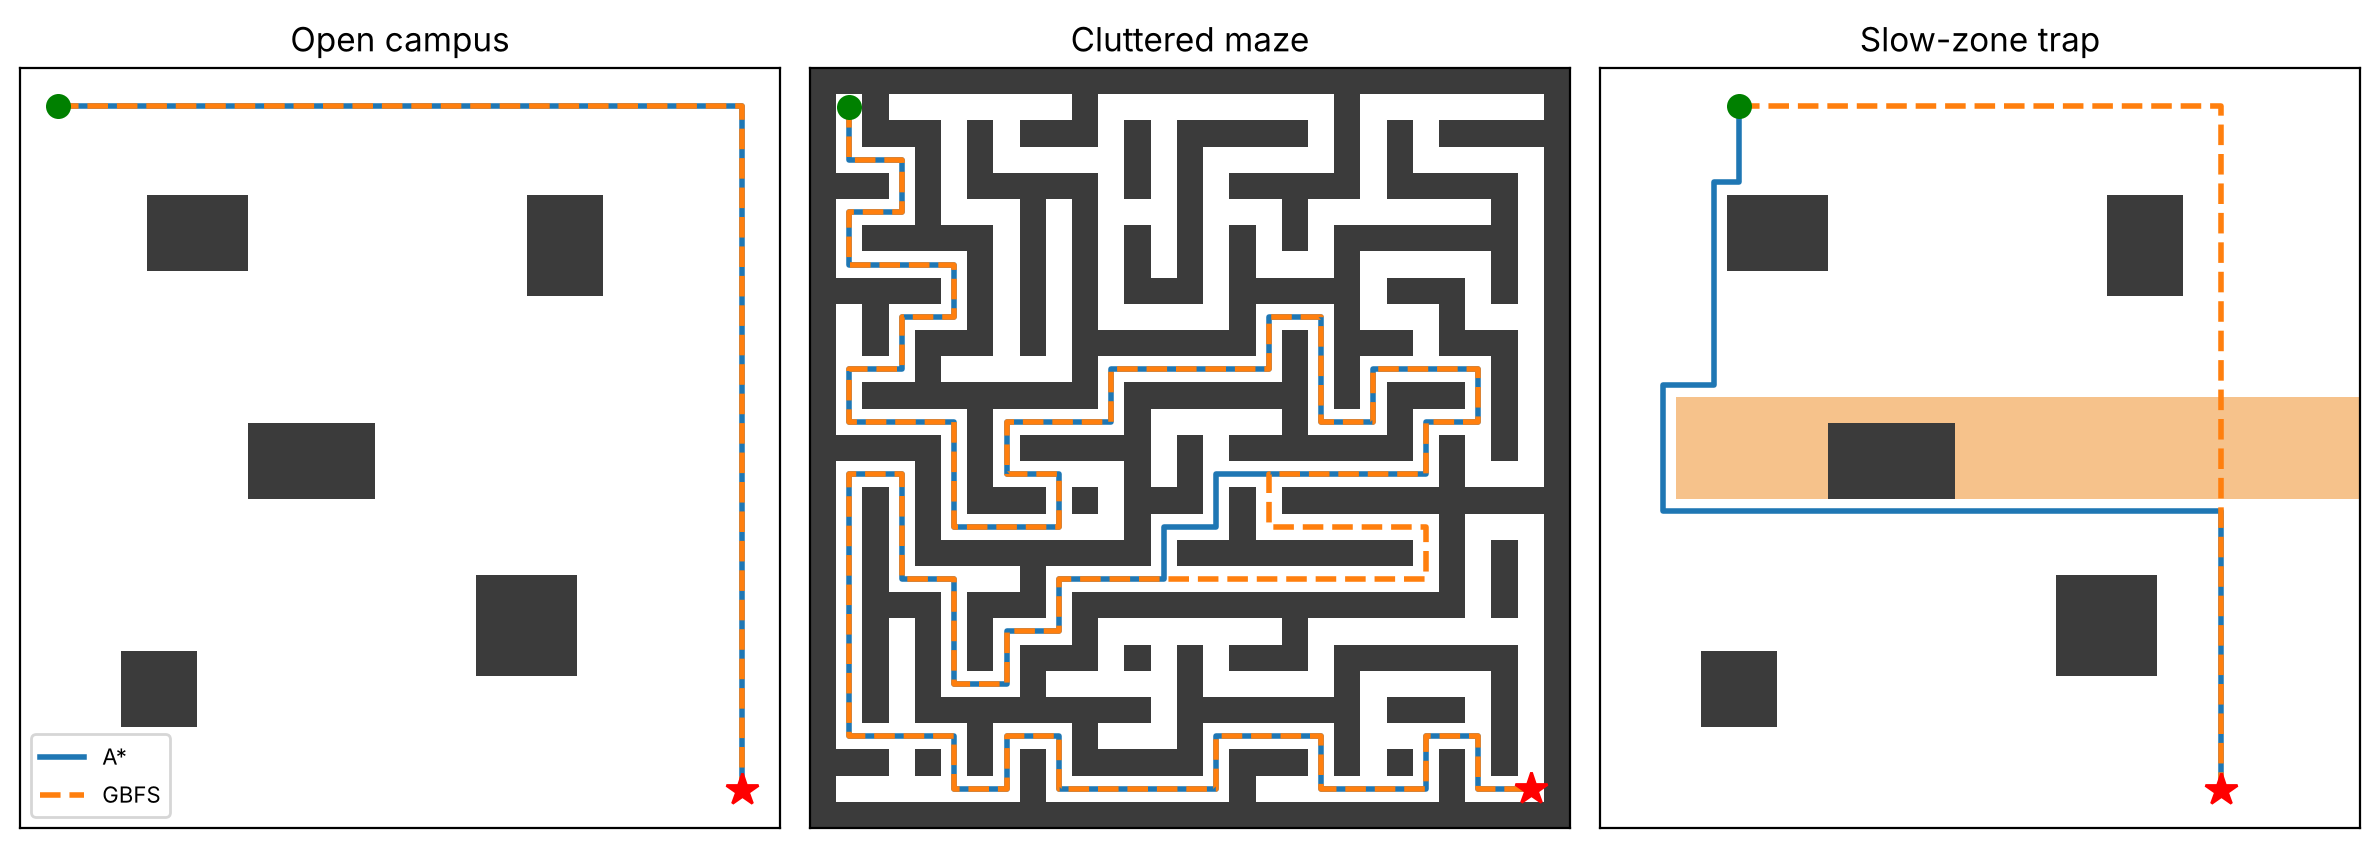

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, (name, maker) in zip(axes, MAPS.items()):
    g, s, t = maker()
    img = [[{'#': 0, '.': 1, 'p': 2}[ch] for ch in row] for row in g]
    ax.imshow(img, cmap=ListedColormap(['#3b3b3b', 'white', '#f6c28b']), vmin=0, vmax=2)
    for mode, style in (('A*', '-'), ('GBFS', '--')):
        path = best_first(g, s, t, mode)[0]
        ax.plot([c for r, c in path], [r for r, c in path], style, lw=2, label=mode)
    ax.plot(s[1], s[0], 'go', ms=8); ax.plot(t[1], t[0], 'r*', ms=12)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.savefig('figures/task1_maps.png', dpi=200); plt.show()

## Task 2 - Online search agent

In [6]:
# Task 2 - Online DFS agent and LRTA* in an unmapped facility
import random
from collections import deque

MOVES = {'N': (-1, 0), 'E': (0, 1), 'S': (1, 0), 'W': (0, -1)}
BACK = {'N': 'S', 'S': 'N', 'E': 'W', 'W': 'E'}

def facility(cells, seed, open_dead_ends=0.0):
    """Perfect maze (many dead ends); a share of dead ends is then opened up."""
    rng = random.Random(seed)
    H = W = 2 * cells + 1
    g = [['#'] * W for _ in range(H)]
    stack, seen = [(0, 0)], {(0, 0)}
    g[1][1] = '.'
    while stack:
        r, c = stack[-1]
        nb = [(r + dr, c + dc) for dr, dc in MOVES.values()
              if 0 <= r + dr < cells and 0 <= c + dc < cells and (r + dr, c + dc) not in seen]
        if not nb:
            stack.pop(); continue
        nr, nc = rng.choice(nb)
        g[r + nr + 1][c + nc + 1] = '.'
        g[2 * nr + 1][2 * nc + 1] = '.'
        seen.add((nr, nc)); stack.append((nr, nc))
    for r in range(cells):
        for c in range(cells):
            cell = (2 * r + 1, 2 * c + 1)
            walls = [d for d, (dr, dc) in MOVES.items()
                     if 1 <= cell[0] + 2 * dr < H - 1 and 1 <= cell[1] + 2 * dc < W - 1
                     and g[cell[0] + dr][cell[1] + dc] == '#']
            if len(walls) == 3 and rng.random() < open_dead_ends:      # dead end: knock one wall
                dr, dc = MOVES[rng.choice(walls)]
                g[cell[0] + dr][cell[1] + dc] = '.'
    return g

def dead_ends(g):
    return sum(1 for r in range(1, len(g), 2) for c in range(1, len(g), 2)
               if sum(g[r + dr][c + dc] == '.' for dr, dc in MOVES.values()) == 1)

def sense(g, s):
    """The rover can only sense which neighbouring cells are open."""
    return [a for a, (dr, dc) in MOVES.items() if g[s[0] + dr][s[1] + dc] != '#']

def step(s, a):
    return (s[0] + MOVES[a][0], s[1] + MOVES[a][1])

def bfs_dist(g, s):
    dist, q = {s: 0}, deque([s])
    while q:
        u = q.popleft()
        for a in sense(g, u):
            v = step(u, a)
            if v not in dist:
                dist[v] = dist[u] + 1; q.append(v)
    return dist

def online_dfs(g, start, goal):
    """Online DFS: the rover knows its own coordinates but not the map.
    It enters an unvisited open neighbour if one exists, otherwise it drives
    back to the cell it came from. Every move is a physical move."""
    path, visited, moves = [start], {start}, 0
    untried = {start: sense(g, start)}
    while path:
        s = path[-1]
        if s == goal:
            return dict(found=True, moves=moves, revisits=moves + 1 - len(visited), explored=len(visited))
        nxt = None
        while untried[s]:
            v = step(s, untried[s].pop(0))
            if v not in visited:
                nxt = v; break
        if nxt is not None:
            path.append(nxt); visited.add(nxt); untried[nxt] = sense(g, nxt); moves += 1
        else:
            path.pop()
            if path:
                moves += 1                            # physical backtrack to the parent
    return dict(found=False, moves=moves, revisits=moves + 1 - len(visited), explored=len(visited))

def lrta_star(g, start, goal, H, cap=200000):
    """One LRTA* trial; H is the learned cost-to-go table shared across trials."""
    h = lambda x: H.get(x, abs(x[0] - goal[0]) + abs(x[1] - goal[1]))
    s, moves, visited = start, 0, {start}
    while s != goal and moves < cap:
        options = [(1 + h(step(s, a)), a) for a in sense(g, s)]
        best, a = min(options)
        H[s] = max(h(s), best)                        # learn: raise the estimate
        s = step(s, a); moves += 1; visited.add(s)
    return dict(found=s == goal, moves=moves, revisits=moves + 1 - len(visited))

def sealed_dock(g, target):
    """Make the dock unreachable: wall in every open neighbour of the dock cell."""
    g2 = [row[:] for row in g]
    for dr, dc in MOVES.values():
        r, c = target[0] + dr, target[1] + dc
        if 0 < r < len(g2) - 1 and 0 < c < len(g2) - 1:
            g2[r][c] = '#'
    return g2

BANDS = [(1, 25), (26, 75), (76, 150), (151, 10 ** 9)]

def distance_experiment(seeds=range(5), cells=20, per_band=10):
    rows = []
    for lo, hi in BANDS:
        crs, mv, rv, n = [], 0, 0, 0
        for sd in seeds:
            g = facility(cells, sd, 0.3)
            d = bfs_dist(g, (1, 1))
            cand = sorted(c for c in d if lo <= d[c] <= hi and c[0] % 2 and c[1] % 2)
            rng = random.Random(100 + sd)
            for t in rng.sample(cand, min(per_band, len(cand))):
                r = online_dfs(g, (1, 1), t)
                crs.append(r['moves'] / d[t]); mv += r['moves']; rv += r['revisits']; n += 1
        rows.append(dict(band=f'{lo}-{hi}' if hi < 10 ** 9 else f'>{lo - 1}', targets=n, moves=mv / n,
                         revisits=rv / n, cr_mean=sum(crs) / n, cr_max=max(crs)))
    return rows

def unreachable_experiment(seeds=range(5)):
    rows = []
    for cells in (10, 20, 40):
        for sd in seeds[:1]:
            g = facility(cells, sd, 0.3)
            far = max(bfs_dist(g, (1, 1)).items(), key=lambda kv: kv[1])[0]
            g2 = sealed_dock(g, far)
            reach = len(bfs_dist(g2, (1, 1)))
            r = online_dfs(g2, (1, 1), far)
            rows.append(dict(cells=cells * cells, reachable=reach, found=r['found'], moves=r['moves'],
                             bound=2 * (reach - 1), revisits=r['revisits']))
    return rows

def size_density_experiment(seeds=range(5)):
    rows = []
    for cells in (10, 20, 40):
        for p in (0.0, 0.5, 1.0):
            crs, de, mv = [], 0, 0
            for sd in seeds:
                g = facility(cells, sd, p)
                d = bfs_dist(g, (1, 1))
                far = max(d, key=d.get)
                r = online_dfs(g, (1, 1), far)
                crs.append(r['moves'] / d[far]); de += dead_ends(g); mv += r['moves']
            rows.append(dict(cells=cells * cells, opened=p, dead_ends=de / len(seeds), moves=mv / len(seeds),
                             cr_mean=sum(crs) / len(crs), cr_max=max(crs)))
    return rows

def lrta_trials(seeds=range(5), cells=20, trials=10):
    per = [[] for _ in range(trials)]
    for sd in seeds:
        g = facility(cells, sd, 0.3)
        d = bfs_dist(g, (1, 1)); far = max(d, key=d.get)
        H = {}
        for k in range(trials):
            per[k].append(lrta_star(g, (1, 1), far, H)['moves'] / d[far])
    return [sum(x) / len(x) for x in per]

In [7]:
print('Targets at different distances (5 facilities, 20 x 20 rooms, 30% of dead ends opened)')
rows = distance_experiment()
for r in rows:
    print(f"distance {r['band']:>7} | targets {r['targets']} | moves {r['moves']:6.1f} | "
          f"revisits {r['revisits']:6.1f} | CR mean {r['cr_mean']:4.2f} | CR max {r['cr_max']:5.2f}")
save_csv('task2_distance.csv', rows)
print('Unreachable dock (dock cell sealed)')
rows = unreachable_experiment()
for r in rows:
    print(f"rooms {r['cells']:5} | reachable cells {r['reachable']:5} | found {r['found']} | "
          f"moves {r['moves']:5} | 2(N-1) = {r['bound']}")
save_csv('task2_unreachable.csv', rows)

Targets at different distances (5 facilities, 20 x 20 rooms, 30% of dead ends opened)
distance    1-25 | targets 50 | moves   13.7 | revisits    0.1 | CR mean 1.01 | CR max  1.18
distance   26-75 | targets 50 | moves  182.2 | revisits   64.6 | CR mean 3.78 | CR max 38.80
distance  76-150 | targets 50 | moves  467.6 | revisits  144.1 | CR mean 4.08 | CR max 18.85
distance    >150 | targets 50 | moves  629.7 | revisits  165.7 | CR mean 3.02 | CR max  8.44
Unreachable dock (dock cell sealed)
rooms   100 | reachable cells   200 | found False | moves   398 | 2(N-1) = 398
rooms   400 | reachable cells   803 | found False | moves  1604 | 2(N-1) = 1604
rooms  1600 | reachable cells  3236 | found False | moves  6470 | 2(N-1) = 6470


In [8]:
print('Maze size x share of dead ends opened (5 seeds each, dock = farthest cell)')
rows = size_density_experiment()
for r in rows:
    print(f"rooms {r['cells']:5} | opened {r['opened']:.1f} | dead ends {r['dead_ends']:6.1f} | "
          f"moves {r['moves']:7.1f} | CR mean {r['cr_mean']:4.2f} | CR max {r['cr_max']:5.2f}")
save_csv('task2_size_density.csv', rows)
cr = lrta_trials()
print('LRTA* competitive ratio by trial:', ' '.join(f'{x:.2f}' for x in cr))
save_csv('task2_lrta.csv', [dict(trial=i + 1, cr=x) for i, x in enumerate(cr)])

Maze size x share of dead ends opened (5 seeds each, dock = farthest cell)


rooms   100 | opened 0.0 | dead ends   12.4 | moves   209.6 | CR mean 1.42 | CR max  1.90
rooms   100 | opened 0.5 | dead ends    8.4 | moves   150.8 | CR mean 1.83 | CR max  2.72
rooms   100 | opened 1.0 | dead ends    5.0 | moves   113.6 | CR mean 1.60 | CR max  2.47
rooms   400 | opened 0.0 | dead ends   42.6 | moves   898.0 | CR mean 2.01 | CR max  2.45
rooms   400 | opened 0.5 | dead ends   28.0 | moves   479.6 | CR mean 2.11 | CR max  2.85
rooms   400 | opened 1.0 | dead ends    8.0 | moves   420.8 | CR mean 2.55 | CR max  6.54
rooms  1600 | opened 0.0 | dead ends  159.2 | moves  3220.0 | CR mean 2.08 | CR max  2.57
rooms  1600 | opened 0.5 | dead ends   87.8 | moves  1839.2 | CR mean 5.05 | CR max 10.24
rooms  1600 | opened 1.0 | dead ends   16.8 | moves  1482.0 | CR mean 5.62 | CR max 15.16


LRTA* competitive ratio by trial: 40.60 2.94 4.13 3.17 3.16 3.15 3.55 3.33 3.43 3.30


## Task 3 - Alpha-beta pruning

In [9]:
# Task 3 - How tree structure and move order drive alpha-beta work
import random

def build(b, d, values):
    """Uniform tree as nested lists; leaves taken from `values` in order."""
    it = iter(values)
    def rec(k):
        return next(it) if k == 0 else [rec(k - 1) for _ in range(b)]
    return rec(d)

def minimax_value(node, maximizing):
    if not isinstance(node, list):
        return node
    vals = [minimax_value(c, not maximizing) for c in node]
    return max(vals) if maximizing else min(vals)

def reorder(node, maximizing, best_first):
    """Sort children by their true minimax value: best-first or worst-first."""
    if not isinstance(node, list):
        return node
    kids = [reorder(c, not maximizing, best_first) for c in node]
    kids.sort(key=lambda c: minimax_value(c, not maximizing),
              reverse=(maximizing == best_first))
    return kids

class Counter:
    def __init__(self):
        self.nodes = self.leaves = self.cutoffs = 0

def minimax_tree(node, maximizing, cnt):
    cnt.nodes += 1
    if not isinstance(node, list):
        cnt.leaves += 1
        return node
    vals = [minimax_tree(c, not maximizing, cnt) for c in node]
    return max(vals) if maximizing else min(vals)

def alphabeta(node, maximizing, cnt, alpha=float('-inf'), beta=float('inf')):
    cnt.nodes += 1
    if not isinstance(node, list):
        cnt.leaves += 1
        return node
    if maximizing:
        v = float('-inf')
        for i, c in enumerate(node):
            v = max(v, alphabeta(c, False, cnt, alpha, beta))
            alpha = max(alpha, v)
            if alpha >= beta:
                if i < len(node) - 1:
                    cnt.cutoffs += 1          # remaining siblings are never visited
                break
        return v
    v = float('inf')
    for i, c in enumerate(node):
        v = min(v, alphabeta(c, True, cnt, alpha, beta))
        beta = min(beta, v)
        if alpha >= beta:
            if i < len(node) - 1:
                cnt.cutoffs += 1
            break
    return v

def no_cutoff_tree(b, d):
    """Engineered so that no cutoff can occur: every child's whole subtree lies in
    its own slice of the parent's value window. MAX children rise, MIN children
    fall, so a new value never crosses the bound inherited from earlier siblings."""
    def gen(k, maximizing, lo, hi):
        if k == 0:
            return (lo + hi) / 2
        w = (hi - lo) / b
        parts = [(lo + i * w, lo + (i + 1) * w) for i in range(b)]
        if not maximizing:
            parts.reverse()
        return [gen(k - 1, not maximizing, p, q) for p, q in parts]
    t = gen(d, True, 0.0, 1.0)
    flat = []
    def walk(n):
        if isinstance(n, list):
            for c in n: walk(c)
        else:
            flat.append(n)
    walk(t)
    rank = {v: i for i, v in enumerate(sorted(flat))}       # integer leaf values
    def relabel(n):
        return [relabel(c) for c in n] if isinstance(n, list) else rank[n]
    return relabel(t)

def predicted_best(b, d):
    """Knuth-Moore minimal tree: level k holds b^ceil(k/2) + b^floor(k/2) - 1 nodes."""
    return sum(b ** ((k + 1) // 2) + b ** (k // 2) - 1 for k in range(d + 1)), b ** ((d + 1) // 2) + b ** (d // 2) - 1

def predicted_full(b, d):
    return (b ** (d + 1) - 1) // (b - 1), b ** d

def trees(b=4, d=4, seed=11):
    rng = random.Random(seed)
    leaves = list(range(b ** d)); rng.shuffle(leaves)
    base = build(b, d, leaves)
    return {
        'Best-first order': reorder(base, True, True),
        'Engineered no-cutoff': no_cutoff_tree(b, d),
        'Random order': base,
        'Equal leaf values': build(b, d, [5] * b ** d),
    }

def run_task3(b=4, d=4):
    rows = []
    for name, t in trees(b, d).items():
        m, a = Counter(), Counter()
        v1, v2 = minimax_tree(t, True, m), alphabeta(t, True, a)
        rows.append(dict(tree=name, value=v1, same=v1 == v2, mm_nodes=m.nodes, ab_nodes=a.nodes,
                         ab_leaves=a.leaves, cutoffs=a.cutoffs, saved=round(100 * (1 - a.nodes / m.nodes), 1)))
    return rows

def random_order_spread(b=4, d=4, trials=200):
    out = []
    for s in range(trials):
        rng = random.Random(1000 + s)
        lv = list(range(b ** d)); rng.shuffle(lv)
        c = Counter(); alphabeta(build(b, d, lv), True, c); out.append(c.nodes)
    out.sort()
    return dict(min=out[0], median=out[len(out) // 2], max=out[-1], mean=sum(out) / len(out))

In [10]:
for d in (4, 6):
    pb, pf = predicted_best(4, d), predicted_full(4, d)
    print(f"b=4, d={d}: predicted best-case {pb[0]} nodes ({pb[1]} leaves); "
          f"no cutoffs {pf[0]} nodes ({pf[1]} leaves)")
    for r in run_task3(4, d):
        print(f"  {r['tree']:21} minimax {r['mm_nodes']:5} | alpha-beta {r['ab_nodes']:5} nodes, "
              f"{r['ab_leaves']:5} leaves, {r['cutoffs']:4} cutoffs | saved {r['saved']:5.1f}% | same value {r['same']}")
    save_csv(f'task3_d{d}.csv', run_task3(4, d))
print('Random order, 200 trees (b=4, d=4):', random_order_spread())

b=4, d=4: predicted best-case 62 nodes (31 leaves); no cutoffs 341 nodes (256 leaves)
  Best-first order      minimax   341 | alpha-beta    62 nodes,    31 leaves,   21 cutoffs | saved  81.8% | same value True
  Engineered no-cutoff  minimax   341 | alpha-beta   341 nodes,   256 leaves,    0 cutoffs | saved   0.0% | same value True
  Random order          minimax   341 | alpha-beta   138 nodes,    90 leaves,   23 cutoffs | saved  59.5% | same value True
  Equal leaf values     minimax   341 | alpha-beta    62 nodes,    31 leaves,   21 cutoffs | saved  81.8% | same value True
b=4, d=6: predicted best-case 268 nodes (127 leaves); no cutoffs 5461 nodes (4096 leaves)
  Best-first order      minimax  5461 | alpha-beta   268 nodes,   127 leaves,   99 cutoffs | saved  95.1% | same value True
  Engineered no-cutoff  minimax  5461 | alpha-beta  5461 nodes,  4096 leaves,    0 cutoffs | saved   0.0% | same value True
  Random order          minimax  5461 | alpha-beta  1736 nodes,  1134 leaves,  3

## Task 4 - Depth-limited minimax

In [11]:
# Task 4 - Depth-limited minimax with an evaluation function (Connect-k on a gravity board)
import random, time

class Game:
    def __init__(self, cols, rows, k):
        self.cols, self.rows, self.k = cols, rows, k
        self.windows = []                     # every line of k cells, precomputed once
        for r in range(rows):
            for c in range(cols):
                for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
                    cells = [(r + i * dr, c + i * dc) for i in range(k)]
                    if all(0 <= rr < rows and 0 <= cc < cols for rr, cc in cells):
                        self.windows.append(cells)

    def start(self):
        return tuple(tuple() for _ in range(self.cols))      # one tuple (bottom-up) per column

    def moves(self, s):
        return [c for c in range(self.cols) if len(s[c]) < self.rows]

    def play(self, s, c, p):
        return s[:c] + (s[c] + (p,),) + s[c + 1:]

    def cell(self, s, r, c):
        return s[c][r] if r < len(s[c]) else 0

    def winner(self, s):
        for w in self.windows:
            a = self.cell(s, *w[0])
            if a and all(self.cell(s, r, c) == a for r, c in w[1:]):
                return a
        return 0

def evaluate(game, s, me):
    """Open-line score: lines still winnable for one side only, weighted by how
    full they are (3 of 4 >> 2 of 4), plus a small centre-column preference."""
    score, opp, k = 0, 3 - me, game.k
    W = {k - 1: 50, k - 2: 5}
    for w in game.windows:
        vals = [game.cell(s, r, c) for r, c in w]
        m, o = vals.count(me), vals.count(opp)
        if o == 0 and m:
            score += W.get(m, 1)
        elif m == 0 and o:
            score -= W.get(o, 1)
    centre = game.cols // 2
    score += 3 * (s[centre].count(me) - s[centre].count(opp))
    return score

WIN = 10 ** 6

class Stats:
    def __init__(self):
        self.nodes = self.expanded = self.evals = 0

def minimax(game, s, depth, player, me, st):
    """Plain depth-limited minimax: every legal move at every level is examined."""
    st.nodes += 1
    w = game.winner(s)
    if w:
        return (WIN + depth) if w == me else -(WIN + depth)     # prefer faster wins
    ms = game.moves(s)
    if not ms:
        return 0
    if depth == 0:
        st.evals += 1
        return evaluate(game, s, me)
    st.expanded += 1
    vals = [minimax(game, game.play(s, c, player), depth - 1, 3 - player, me, st) for c in ms]
    return max(vals) if player == me else min(vals)

def choose(game, s, depth, me, st=None):
    st = st or Stats()
    best, best_v = None, -float('inf')
    st.nodes += 1; st.expanded += 1
    for c in game.moves(s):
        v = minimax(game, game.play(s, c, me), depth - 1, 3 - me, me, st)
        if v > best_v:
            best, best_v = c, v
    return best, best_v, st

def predicted_nodes(b, d):
    return sum(b ** i for i in range(d + 1)), b ** d

def play_vs_random(game, depth, games=20, seed=0, chooser=choose):
    rng = random.Random(seed)
    res = {'win': 0, 'draw': 0, 'loss': 0}
    for g in range(games):
        ai = 1 if g % 2 == 0 else 2                # AI moves first in half the games
        s, p = game.start(), 1
        while True:
            w = game.winner(s)
            if w or not game.moves(s):
                res['win' if w == ai else 'loss' if w else 'draw'] += 1
                break
            c = chooser(game, s, depth, ai)[0] if p == ai else rng.choice(game.moves(s))
            s, p = game.play(s, c, p), 3 - p
    return res

BOARDS = {'5x4, connect-3': (5, 4, 3), '6x5, connect-4': (6, 5, 4), '7x6, connect-4': (7, 6, 4)}

def play_vs_greedy(game, depth, games=20, seed=0, opening=2, chooser=choose):
    """Stronger yardstick: opponent is depth-1 minimax; the first `opening` plies
    of each game are random so that the 20 games differ."""
    rng = random.Random(seed)
    res = {'win': 0, 'draw': 0, 'loss': 0}
    for g in range(games):
        ai = 1 if g % 2 == 0 else 2
        s, p, ply = game.start(), 1, 0
        while True:
            w = game.winner(s)
            if w or not game.moves(s):
                res['win' if w == ai else 'loss' if w else 'draw'] += 1
                break
            if ply < opening:
                c = rng.choice(game.moves(s))
            elif p == ai:
                c = chooser(game, s, depth, ai)[0]
            else:
                c = choose(game, s, 1, p)[0]
            s, p, ply = game.play(s, c, p), 3 - p, ply + 1
    return res

In [12]:
rows = []
for name, (c, r, k) in BOARDS.items():
    g = Game(c, r, k)
    for d in range(1, 6 if c < 7 else 7):
        t0 = time.perf_counter(); mv, v, st = choose(g, g.start(), d, 1)
        ms = (time.perf_counter() - t0) * 1000
        pn, pe = predicted_nodes(c, d)
        rows.append(dict(board=name, b=c, depth=d, nodes=st.nodes, predicted=pn, evals=st.evals,
                         b_pow_d=pe, ms=round(ms, 1)))
        print(f"{name} d={d}: nodes {st.nodes:6} (formula {pn:6}) | evals {st.evals:6} (b^d {pe:6}) | {ms:7.1f} ms")
save_csv('task4_growth.csv', rows)

5x4, connect-3 d=1: nodes      6 (formula      6) | evals      5 (b^d      5) |     0.2 ms
5x4, connect-3 d=2: nodes     31 (formula     31) | evals     25 (b^d     25) |     0.7 ms
5x4, connect-3 d=3: nodes    156 (formula    156) | evals    125 (b^d    125) |     2.9 ms
5x4, connect-3 d=4: nodes    781 (formula    781) | evals    625 (b^d    625) |    15.4 ms
5x4, connect-3 d=5: nodes   3901 (formula   3906) | evals   2824 (b^d   3125) |    74.1 ms
6x5, connect-4 d=1: nodes      7 (formula      7) | evals      6 (b^d      6) |     0.1 ms
6x5, connect-4 d=2: nodes     43 (formula     43) | evals     36 (b^d     36) |     1.1 ms
6x5, connect-4 d=3: nodes    259 (formula    259) | evals    216 (b^d    216) |     5.9 ms


6x5, connect-4 d=4: nodes   1555 (formula   1555) | evals   1296 (b^d   1296) |    40.4 ms


6x5, connect-4 d=5: nodes   9331 (formula   9331) | evals   7776 (b^d   7776) |   254.7 ms
7x6, connect-4 d=1: nodes      8 (formula      8) | evals      7 (b^d      7) |     0.3 ms
7x6, connect-4 d=2: nodes     57 (formula     57) | evals     49 (b^d     49) |     2.0 ms
7x6, connect-4 d=3: nodes    400 (formula    400) | evals    343 (b^d    343) |    15.2 ms
7x6, connect-4 d=4: nodes   2801 (formula   2801) | evals   2401 (b^d   2401) |   106.5 ms


7x6, connect-4 d=5: nodes  19608 (formula  19608) | evals  16807 (b^d  16807) |  1200.8 ms


7x6, connect-4 d=6: nodes 137257 (formula 137257) | evals 117649 (b^d 117649) |  6471.7 ms


In [13]:
rows = []
for name, (c, r, k) in BOARDS.items():
    g = Game(c, r, k)
    for d in (1, 2, 3, 4):
        a, b = play_vs_random(g, d), play_vs_greedy(g, d)
        rows.append(dict(board=name, depth=d, vs_random=a['win'], vs_greedy_w=b['win'],
                         vs_greedy_d=b['draw'], vs_greedy_l=b['loss']))
        print(f"{name} d={d}: vs random {a['win']}/20 wins | vs depth-1 AI W-D-L "
              f"{b['win']}-{b['draw']}-{b['loss']}")
save_csv('task4_games.csv', rows)

5x4, connect-3 d=1: vs random 18/20 wins | vs depth-1 AI W-D-L 9-0-11
5x4, connect-3 d=2: vs random 18/20 wins | vs depth-1 AI W-D-L 13-0-7


5x4, connect-3 d=3: vs random 19/20 wins | vs depth-1 AI W-D-L 13-0-7


5x4, connect-3 d=4: vs random 19/20 wins | vs depth-1 AI W-D-L 13-0-7
6x5, connect-4 d=1: vs random 20/20 wins | vs depth-1 AI W-D-L 12-0-8


6x5, connect-4 d=2: vs random 20/20 wins | vs depth-1 AI W-D-L 17-3-0


6x5, connect-4 d=3: vs random 19/20 wins | vs depth-1 AI W-D-L 15-5-0


6x5, connect-4 d=4: vs random 20/20 wins | vs depth-1 AI W-D-L 15-3-2
7x6, connect-4 d=1: vs random 20/20 wins | vs depth-1 AI W-D-L 12-0-8


7x6, connect-4 d=2: vs random 20/20 wins | vs depth-1 AI W-D-L 17-2-1


7x6, connect-4 d=3: vs random 20/20 wins | vs depth-1 AI W-D-L 17-0-3


7x6, connect-4 d=4: vs random 20/20 wins | vs depth-1 AI W-D-L 16-1-3


## Task 5 - Constraint propagation

In [14]:
# Task 5 - Constraint propagation for exam timetabling, derived from the support principle
import random, time
from collections import deque

class Timetable:
    """Variables = exams, domain = allowed slots, constraint = 'different slot'
    for every pair of exams that share at least one student."""
    def __init__(self, domains, clashes):
        self.domains = {x: set(d) for x, d in domains.items()}
        self.nb = {x: set() for x in domains}
        for a, b in clashes:
            self.nb[a].add(b); self.nb[b].add(a)

    @staticmethod
    def compatible(x_slot, y_slot):
        return x_slot != y_slot

class Count:
    def __init__(self):
        self.checks = self.nodes = self.backtracks = self.wipeouts = self.removed = 0

def revise(D, xi, xj, cnt, log=None, step=None):
    """Remove every value of xi that has no compatible value left in xj."""
    removed = False
    for v in sorted(D[xi]):
        supported = False
        for w in D[xj]:
            cnt.checks += 1
            if Timetable.compatible(v, w):
                supported = True
                break
        if not supported:
            D[xi].discard(v); removed = True; cnt.removed += 1
            if log is not None:
                log.append((step[0], xi, v))
    return removed

def propagate(csp, D, cnt, arcs=None, log=None):
    """Arc queue: after xi loses a value, every arc (xk, xi) must be re-examined,
    because xk's values may have depended on the value that just disappeared."""
    q = deque(arcs if arcs is not None else [(x, y) for x in csp.nb for y in sorted(csp.nb[x])])
    queued = set(q)
    step = [0]
    while q:
        xi, xj = q.popleft(); queued.discard((xi, xj)); step[0] += 1
        if revise(D, xi, xj, cnt, log, step):
            if not D[xi]:
                cnt.wipeouts += 1
                return False                    # empty domain: no solution below this point
            for xk in sorted(csp.nb[xi] - {xj}):
                if (xk, xi) not in queued:
                    q.append((xk, xi)); queued.add((xk, xi))
    return True

def order(csp):
    return sorted(csp.nb, key=lambda x: (-len(csp.nb[x]), x))   # same static order for both

def backtrack_plain(csp, cap=200_000):
    cnt, A, xs = Count(), {}, order(csp)
    def bt(i):
        if i == len(xs):
            return True
        if cnt.nodes >= cap:
            return False
        x = xs[i]
        for v in sorted(csp.domains[x]):
            ok = True
            for y in sorted(csp.nb[x]):
                if y in A:
                    cnt.checks += 1
                    if not Timetable.compatible(v, A[y]):
                        ok = False; break
            if ok:
                cnt.nodes += 1; A[x] = v
                if bt(i + 1):
                    return True
                del A[x]; cnt.backtracks += 1
        return False
    found = bt(0)
    return (A if found else None), cnt, cnt.nodes >= cap

def backtrack_mac(csp, cap=200_000):
    """Backtracking that re-runs propagation after every assignment."""
    cnt, xs = Count(), order(csp)
    D0 = {x: set(d) for x, d in csp.domains.items()}
    if not propagate(csp, D0, cnt):
        return None, cnt, False
    def bt(i, D):
        if i == len(xs):
            return {x: next(iter(D[x])) for x in xs}
        if cnt.nodes >= cap:
            return None
        x = xs[i]
        for v in sorted(D[x]):
            cnt.nodes += 1
            D2 = {y: set(d) for y, d in D.items()}
            D2[x] = {v}
            if propagate(csp, D2, cnt, arcs=[(y, x) for y in sorted(csp.nb[x])]):
                sol = bt(i + 1, D2)
                if sol:
                    return sol
            cnt.backtracks += 1
        return None
    sol = bt(0, D0)
    return sol, cnt, cnt.nodes >= cap

def valid(csp, A):
    return A is not None and all(A[x] in csp.domains[x] and all(A[x] != A[y] for y in csp.nb[x]) for x in csp.nb)

# ---------- designed instances ----------
SLOTS = ['Mon-AM', 'Mon-PM', 'Tue-AM', 'Tue-PM']

def instance_forced():
    """Instance 1: two exams are pre-booked (hall availability). Propagation alone
    pins every exam to a single slot - no search needed."""
    exams = ['AI', 'DBMS', 'OS', 'CN', 'Maths', 'Physics', 'Bio', 'Chem']
    dom = {e: set(range(4)) for e in exams}
    dom['AI'] = {0}; dom['DBMS'] = {1}
    dom['OS'] = {0, 1, 2}; dom['Maths'] = {1, 2, 3}; dom['Physics'] = {0, 2, 3}
    clashes = [('AI', 'OS'), ('DBMS', 'OS'), ('OS', 'CN'), ('AI', 'CN'), ('DBMS', 'CN'),
               ('CN', 'Maths'), ('OS', 'Maths'), ('Maths', 'Physics'), ('AI', 'Physics'),
               ('CN', 'Physics'), ('Physics', 'Bio'), ('Maths', 'Bio'), ('OS', 'Bio'), ('CN', 'Bio'),
               ('Bio', 'Chem'), ('Physics', 'Chem'), ('AI', 'Chem'), ('DBMS', 'Chem')]
    return Timetable(dom, clashes)

def instance_infeasible():
    """Same timetable, but the CN hall is unavailable on Tue-PM (slot 3):
    propagation detects the impossibility without assigning anything."""
    csp = instance_forced()
    csp.domains['CN'] = {0, 1, 2}
    return csp

def instance_challenge():
    """Instance 2: five exams that pairwise share students, four slots. Every value
    keeps a support, so propagation removes nothing; only search proves failure."""
    exams = ['E1', 'E2', 'E3', 'E4', 'E5']
    return Timetable({e: set(range(4)) for e in exams}, [(a, b) for i, a in enumerate(exams) for b in exams[i + 1:]])

def random_timetable(n, slots=4, avg_degree=6.0, seed=0, prebooked=0.1):
    """Solvable random instance: a hidden timetable is planted first, clashes are
    only drawn between exams in different hidden slots."""
    rng = random.Random(seed)
    hidden = {i: rng.randrange(slots) for i in range(n)}
    pairs = [(a, b) for a in range(n) for b in range(a + 1, n) if hidden[a] != hidden[b]]
    m = min(len(pairs), int(avg_degree * n / 2))
    clashes = rng.sample(pairs, m)
    dom = {i: set(range(slots)) for i in range(n)}
    for i in rng.sample(range(n), max(1, int(prebooked * n))):
        dom[i] = {hidden[i]}
    return Timetable(dom, clashes)

In [15]:
for name, make in (('Instance 1 (pre-booked)', instance_forced),
                   ('Instance 1b (CN hall closed Tue-PM)', instance_infeasible),
                   ('Instance 2 (5 exams, 4 slots)', instance_challenge)):
    csp = make(); D = {x: set(d) for x, d in csp.domains.items()}; c = Count()
    ok = propagate(csp, D, c)
    print(f"{name}: consistent={ok}, checks={c.checks}, values removed={c.removed}")
    print('   domains:', {x: [SLOTS[v] for v in sorted(d)] for x, d in D.items()})
    for alg in (backtrack_plain, backtrack_mac):
        A, k, capped = alg(make())
        print(f"   {alg.__name__:15} solution={'valid' if valid(make(), A) else 'none'} nodes={k.nodes} "
              f"backtracks={k.backtracks} checks={k.checks} wipe-outs={k.wipeouts}")

Instance 1 (pre-booked): consistent=True, checks=98, values removed=15
   domains: {'AI': ['Mon-AM'], 'DBMS': ['Mon-PM'], 'OS': ['Tue-AM'], 'CN': ['Tue-PM'], 'Maths': ['Mon-PM'], 'Physics': ['Tue-AM'], 'Bio': ['Mon-AM'], 'Chem': ['Tue-PM']}
   backtrack_plain solution=valid nodes=70 backtracks=62 checks=336 wipe-outs=0
   backtrack_mac   solution=valid nodes=8 backtracks=0 checks=134 wipe-outs=0
Instance 1b (CN hall closed Tue-PM): consistent=False, checks=30, values removed=5
   domains: {'AI': ['Mon-AM'], 'DBMS': ['Mon-PM'], 'OS': ['Tue-AM'], 'CN': [], 'Maths': ['Mon-PM', 'Tue-AM', 'Tue-PM'], 'Physics': ['Mon-AM', 'Tue-AM', 'Tue-PM'], 'Bio': ['Mon-AM', 'Mon-PM', 'Tue-AM', 'Tue-PM'], 'Chem': ['Mon-AM', 'Mon-PM', 'Tue-AM', 'Tue-PM']}
   backtrack_plain solution=none nodes=55 backtracks=55 checks=260 wipe-outs=0
   backtrack_mac   solution=none nodes=0 backtracks=0 checks=30 wipe-outs=1
Instance 2 (5 exams, 4 slots): consistent=True, checks=100, values removed=0
   domains: {'E1': ['Mon

In [16]:
rows = []
for n in (10, 20, 40, 80, 160):
    for alg in (backtrack_plain, backtrack_mac):
        tot = dict(nodes=0, backtracks=0, checks=0, wipeouts=0, capped=0)
        for sd in range(5):
            csp = random_timetable(n, seed=sd); A, k, capped = alg(csp)
            assert capped or valid(csp, A)
            for f in ('nodes', 'backtracks', 'checks', 'wipeouts'):
                tot[f] += getattr(k, f) / 5
            tot['capped'] += capped
        rows.append(dict(exams=n, method=alg.__name__, **tot))
        print(f"n={n:3} {alg.__name__:15} nodes {tot['nodes']:9.1f} | backtracks {tot['backtracks']:9.1f} | "
              f"checks {tot['checks']:10.1f} | wipe-outs {tot['wipeouts']:4.1f} | hit cap {tot['capped']}/5")
save_csv('task5_growth.csv', rows)

n= 10 backtrack_plain nodes      42.4 | backtracks      32.4 | checks      254.0 | wipe-outs  0.0 | hit cap 0/5
n= 10 backtrack_mac   nodes      10.0 | backtracks       0.0 | checks      564.2 | wipe-outs  0.0 | hit cap 0/5
n= 20 backtrack_plain nodes     313.0 | backtracks     293.0 | checks     2154.0 | wipe-outs  0.0 | hit cap 0/5
n= 20 backtrack_mac   nodes      21.2 | backtracks       1.2 | checks     1192.2 | wipe-outs  0.8 | hit cap 0/5
n= 40 backtrack_plain nodes    4324.2 | backtracks    4284.2 | checks    37244.2 | wipe-outs  0.0 | hit cap 0/5
n= 40 backtrack_mac   nodes      40.6 | backtracks       0.6 | checks     2437.8 | wipe-outs  0.6 | hit cap 0/5


n= 80 backtrack_plain nodes  200041.8 | backtracks  200041.8 | checks  1648302.2 | wipe-outs  0.0 | hit cap 5/5
n= 80 backtrack_mac   nodes      83.6 | backtracks       3.6 | checks     5365.2 | wipe-outs  2.0 | hit cap 0/5


n=160 backtrack_plain nodes  200045.2 | backtracks  200045.2 | checks  1056844.2 | wipe-outs  0.0 | hit cap 5/5
n=160 backtrack_mac   nodes     160.0 | backtracks       0.0 | checks     9665.2 | wipe-outs  0.0 | hit cap 0/5


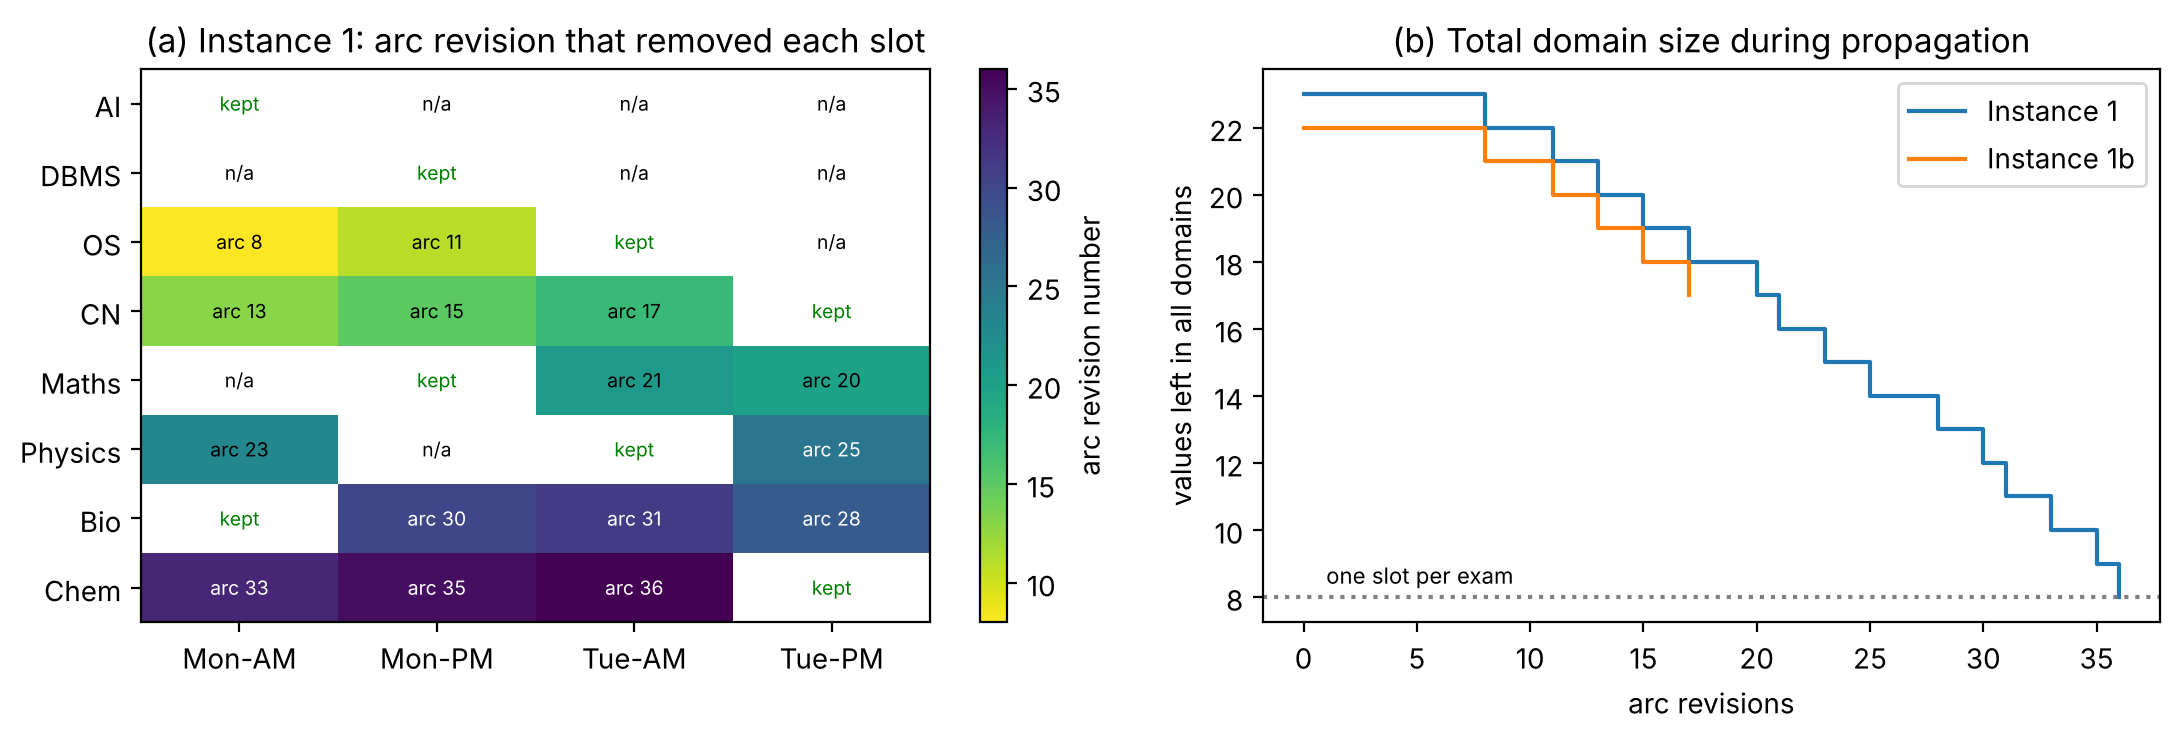

In [17]:
import matplotlib.pyplot as plt
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.1, 1]))
csp = instance_forced(); D = {x: set(d) for x, d in csp.domains.items()}
log = []; propagate(csp, D, Count(), log=log)
exams = list(csp.domains); M = [[0 if v in csp.domains[e] else -1 for v in range(4)] for e in exams]
for stp, x, v in log:
    M[exams.index(x)][v] = stp
im = a1.imshow([[m if m > 0 else float('nan') for m in row] for row in M], cmap='viridis_r', aspect='auto')
for i, e in enumerate(exams):
    for v in range(4):
        txt = 'kept' if v in D[e] else ('n/a' if M[i][v] == -1 else f'arc {M[i][v]}')
        a1.text(v, i, txt, ha='center', va='center', fontsize=7,
                color='green' if txt == 'kept' else ('white' if M[i][v] > 24 else 'black'))
a1.set_xticks(range(4)); a1.set_xticklabels(SLOTS); a1.set_yticks(range(len(exams))); a1.set_yticklabels(exams)
a1.set_title('(a) Instance 1: arc revision that removed each slot'); fig.colorbar(im, ax=a1, label='arc revision number')
for make, lab in ((instance_forced, 'Instance 1'), (instance_infeasible, 'Instance 1b')):
    csp = make(); D = {x: set(d) for x, d in csp.domains.items()}; log = []
    propagate(csp, D, Count(), log=log)
    total = sum(len(d) for d in csp.domains.values()); xs, ys = [0], [total]
    for stp, x, v in log:
        total -= 1; xs.append(stp); ys.append(total)
    a2.step(xs, ys, where='post', label=lab)
a2.axhline(len(exams), ls=':', c='grey'); a2.text(1, len(exams) + 0.4, 'one slot per exam', fontsize=8)
a2.set_xlabel('arc revisions'); a2.set_ylabel('values left in all domains'); a2.legend()
a2.set_title('(b) Total domain size during propagation')
plt.tight_layout(); plt.savefig('figures/task5_domains.png', dpi=200); plt.show()

## Task 6 - Exhaustive and local search

In [18]:
# Task 6 - Exhaustive enumeration vs 2-opt local search for the delivery tour
import itertools, math, random, time

def customers(n, seed=1, size=100):
    rng = random.Random(seed)
    depot = (50.0, 50.0)
    return [depot] + [(rng.uniform(0, size), rng.uniform(0, size)) for _ in range(n)]

def dist_matrix(pts):
    return [[math.dist(a, b) for b in pts] for a in pts]

def tour_length(D, order):
    """order lists customers 1..n; the tour starts and ends at the depot (0)."""
    total, prev = 0.0, 0
    for c in order:
        total += D[prev][c]; prev = c
    return total + D[prev][0]

def exhaustive(D):
    """Fix the depot, enumerate every ordering of the customers, skip each tour's
    mirror image (first customer > last customer) and keep the shortest."""
    n = len(D) - 1
    best, best_len, evaluated = None, float('inf'), 0
    for perm in itertools.permutations(range(1, n + 1)):
        if n > 2 and perm[0] > perm[-1]:
            continue                                    # reverse of a tour already seen
        evaluated += 1
        L = tour_length(D, perm)
        if L < best_len:
            best, best_len = perm, L
    return best, best_len, evaluated

def predicted_tours(n):
    return math.factorial(n) // 2 if n > 2 else 1

def two_opt(D, order, rng=None):
    """Hill climbing: reverse a segment whenever that shortens the tour; stop when
    no 2-opt move improves (a local minimum)."""
    t = [0] + list(order) + [0]
    improved, moves = True, 0
    while improved:
        improved = False
        for i in range(1, len(t) - 2):
            for j in range(i + 1, len(t) - 1):
                a, b, c, d = t[i - 1], t[i], t[j], t[j + 1]
                delta = D[a][c] + D[b][d] - D[a][b] - D[c][d]
                if delta < -1e-12:
                    t[i:j + 1] = reversed(t[i:j + 1]); improved = True; moves += 1
    return t[1:-1], tour_length(D, t[1:-1]), moves

def local_search(D, restarts, rng):
    n = len(D) - 1
    best, best_len = None, float('inf')
    for _ in range(restarts):
        start = list(range(1, n + 1)); rng.shuffle(start)
        o, L, _ = two_opt(D, start)
        if L < best_len:
            best, best_len = o, L
    return best, best_len

def verification_instance():
    """Depot at the middle of the bottom edge of a 40 x 30 km rectangle, four
    customers at the corners: the optimum is the perimeter, 140 km."""
    return [(20.0, 0.0), (0.0, 0.0), (0.0, 30.0), (40.0, 30.0), (40.0, 0.0)]

def all_tours(D):
    n = len(D) - 1
    return [(p, tour_length(D, p)) for p in itertools.permutations(range(1, n + 1)) if p[0] < p[-1]]

def local_search_study(sizes=(8, 9, 10), runs=20, restarts=(1, 10), seed=1):
    rows = []
    for n in sizes:
        D = dist_matrix(customers(n, seed))
        _, opt, _ = exhaustive(D)
        for R in restarts:
            ex, ts, hits = [], [], 0
            for r in range(runs):
                rng = random.Random(1000 * n + r)
                t0 = time.perf_counter()
                _, L = local_search(D, R, rng)
                ts.append((time.perf_counter() - t0) * 1000)
                e = 100 * (L - opt) / opt
                ex.append(e); hits += e < 1e-9
            rows.append(dict(n=n, restarts=R, optimum=round(opt, 2), mean_excess=sum(ex) / runs,
                             worst_excess=max(ex), optimal_runs=hits, mean_ms=sum(ts) / runs))
    return rows

def local_search_large(sizes=(20, 50, 100), restarts=10, seed=1):
    rows = []
    for n in sizes:
        D = dist_matrix(customers(n, seed)); rng = random.Random(n)
        t0 = time.perf_counter(); _, L = local_search(D, restarts, rng)
        rows.append(dict(n=n, length=round(L, 2), ms=(time.perf_counter() - t0) * 1000))
    return rows

In [19]:
D = dist_matrix(verification_instance())
for p, L in sorted(all_tours(D), key=lambda x: x[1]):
    print('depot ->', ' -> '.join(map(str, p)), f'-> depot  {L:7.2f} km')
best, L, k = exhaustive(D)
print('exhaustive search:', best, round(L, 2), 'km after', k, 'tours (perimeter = 140 km)')

depot -> 1 -> 2 -> 3 -> 4 -> depot   140.00 km
depot -> 1 -> 2 -> 4 -> 3 -> depot   166.06 km
depot -> 1 -> 4 -> 3 -> 2 -> depot   166.06 km
depot -> 2 -> 1 -> 3 -> 4 -> depot   166.06 km
depot -> 3 -> 2 -> 1 -> 4 -> depot   166.06 km
depot -> 2 -> 1 -> 4 -> 3 -> depot   172.11 km
depot -> 1 -> 3 -> 2 -> 4 -> depot   180.00 km
depot -> 1 -> 3 -> 4 -> 2 -> depot   186.06 km
depot -> 1 -> 4 -> 2 -> 3 -> depot   186.06 km
depot -> 2 -> 3 -> 1 -> 4 -> depot   186.06 km
depot -> 3 -> 1 -> 2 -> 4 -> depot   186.06 km
depot -> 2 -> 4 -> 1 -> 3 -> depot   212.11 km
exhaustive search: (1, 2, 3, 4) 140.0 km after 12 tours (perimeter = 140 km)


In [20]:
rows = []
for n in range(6, 12):
    D = dist_matrix(customers(n)); t0 = time.perf_counter()
    best, L, k = exhaustive(D); ms = (time.perf_counter() - t0) * 1000
    rows.append(dict(n=n, tours=k, predicted=predicted_tours(n), best=round(L, 2), ms=round(ms, 1)))
    print(f"n={n:2}: tours {k:9} (n!/2 = {predicted_tours(n):9}) | best {L:7.2f} km | {ms:9.1f} ms")
save_csv('task6_growth.csv', rows)

n= 6: tours       360 (n!/2 =       360) | best  292.57 km |       0.1 ms
n= 7: tours      2520 (n!/2 =      2520) | best  317.18 km |       1.0 ms
n= 8: tours     20160 (n!/2 =     20160) | best  320.37 km |       9.0 ms
n= 9: tours    181440 (n!/2 =    181440) | best  329.76 km |      82.0 ms


n=10: tours   1814400 (n!/2 =   1814400) | best  345.00 km |    1086.8 ms


n=11: tours  19958400 (n!/2 =  19958400) | best  349.03 km |   10691.6 ms


In [21]:
rows = local_search_study()
for r in rows:
    print(f"n={r['n']:2} restarts={r['restarts']:2}: mean excess {max(0, r['mean_excess']):5.2f}% | "
          f"worst {r['worst_excess']:5.2f}% | optimal in {r['optimal_runs']:2}/20 runs | {r['mean_ms']:6.3f} ms")
save_csv('task6_local.csv', rows)
for r in local_search_large():
    print(f"n={r['n']:3}: 2-opt x10 restarts tour {r['length']:7.2f} km in {r['ms']:6.1f} ms")

n= 8 restarts= 1: mean excess  0.00% | worst  0.00% | optimal in 10/20 runs |  0.018 ms
n= 8 restarts=10: mean excess  0.00% | worst  0.00% | optimal in 20/20 runs |  0.150 ms
n= 9 restarts= 1: mean excess  0.44% | worst  0.55% | optimal in  4/20 runs |  0.021 ms
n= 9 restarts=10: mean excess  0.03% | worst  0.54% | optimal in 19/20 runs |  0.179 ms
n=10 restarts= 1: mean excess  1.18% | worst  6.67% | optimal in 10/20 runs |  0.025 ms
n=10 restarts=10: mean excess  0.00% | worst  0.00% | optimal in 20/20 runs |  0.218 ms
n= 20: 2-opt x10 restarts tour  416.96 km in    0.9 ms
n= 50: 2-opt x10 restarts tour  647.13 km in    7.2 ms
n=100: 2-opt x10 restarts tour  846.51 km in   35.0 ms


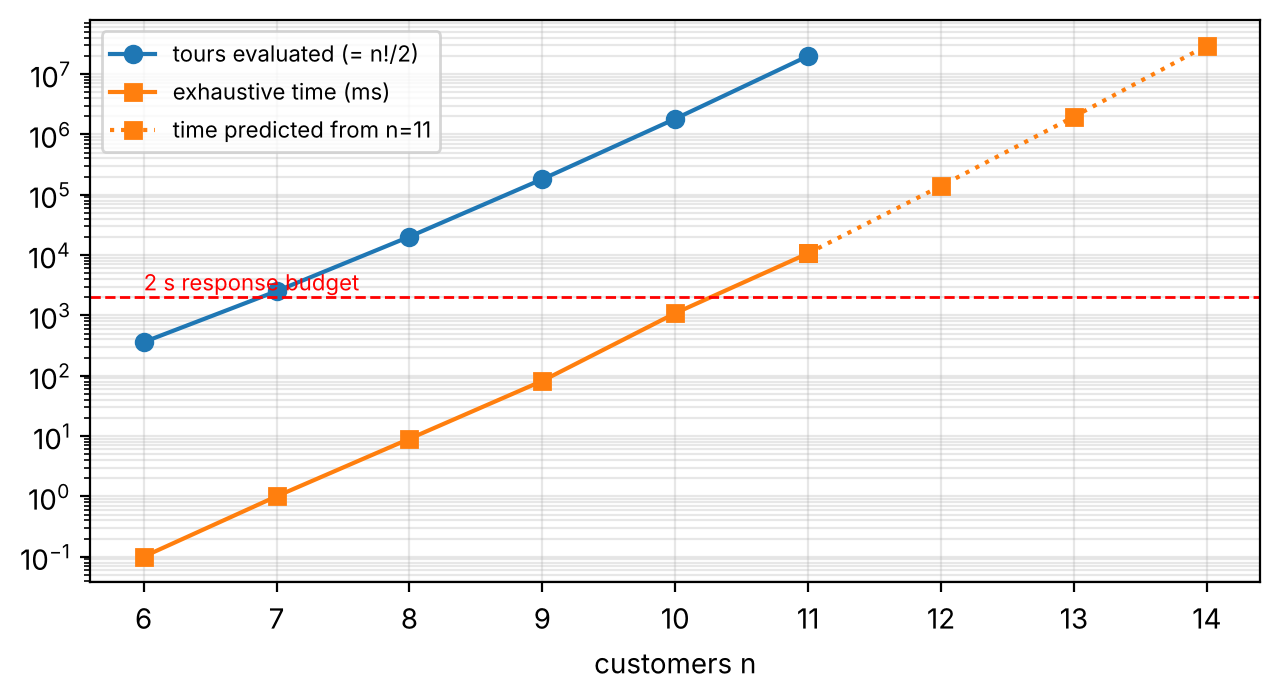

In [22]:
import matplotlib.pyplot as plt, csv
g = list(csv.DictReader(open('data/task6_growth.csv')))
n = [int(r['n']) for r in g]; ms = [float(r['ms']) for r in g]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogy(n, [int(r['tours']) for r in g], 'o-', label='tours evaluated (= n!/2)')
ax.semilogy(n, ms, 's-', label='exhaustive time (ms)')
ext = list(range(11, 15)); ax.semilogy(ext, [ms[-1] * math.factorial(m) / math.factorial(11) * m / 11 for m in ext],
                                       's:', color='C1', label='time predicted from n=11')
ax.axhline(2000, c='red', ls='--', lw=1); ax.text(6, 2600, '2 s response budget', color='red', fontsize=8)
ax.set_xlabel('customers n'); ax.legend(fontsize=8); ax.grid(alpha=.3, which='both')
plt.tight_layout(); plt.savefig('figures/task6_growth.png', dpi=200); plt.show()

## Task 7 - Diagnose, redesign and validate (Task 4 minimax)

In [23]:
# Task 7 - Diagnose and redesign the Task 4 minimax
import random, time

def count_transpositions(game, s, depth, player):
    """How many of the leaf evaluations in plain minimax repeat a position?"""
    leaves, seen = 0, set()
    def walk(s, d, p):
        nonlocal leaves
        if game.winner(s) or not game.moves(s):
            return
        if d == 0:
            leaves += 1; seen.add(s); return
        for c in game.moves(s):
            walk(game.play(s, c, p), d - 1, 3 - p)
    walk(s, depth, player)
    return leaves, len(seen)

EXACT, LOWER, UPPER = 0, 1, 2

def ordered(game, s):
    """Centre-first move order: central columns take part in the most lines."""
    m = game.cols // 2
    return sorted(game.moves(s), key=lambda c: abs(c - m))

USE = dict(table=True, bounds=True, order=True)      # switches for the ablation study

def search(game, s, depth, alpha, beta, player, me, st, table):
    """Bound-passing minimax with a position table. Gives the same value as plain
    minimax to the same depth, but skips moves that cannot change the decision
    and reuses values of positions reached by a different move order."""
    st.nodes += 1
    key = (s, depth, player)
    hit = table.get(key) if USE['table'] else None
    if hit is not None:
        v, flag = hit
        if flag == EXACT or (flag == LOWER and v >= beta) or (flag == UPPER and v <= alpha):
            st.reused += 1
            return v
    w = game.winner(s)
    if w:
        return (WIN + depth) if w == me else -(WIN + depth)
    ms = ordered(game, s) if USE['order'] else game.moves(s)
    if not ms:
        return 0
    if depth == 0:
        st.evals += 1
        v = evaluate(game, s, me)
        if USE['table']:
            table[key] = (v, EXACT)
        return v
    st.expanded += 1
    a0, b0 = alpha, beta
    if player == me:
        v = -float('inf')
        for c in ms:
            v = max(v, search(game, game.play(s, c, player), depth - 1, alpha, beta, 3 - player, me, st, table))
            alpha = max(alpha, v) if USE['bounds'] else alpha
            if alpha >= beta:
                st.cutoffs += 1; break
    else:
        v = float('inf')
        for c in ms:
            v = min(v, search(game, game.play(s, c, player), depth - 1, alpha, beta, 3 - player, me, st, table))
            beta = min(beta, v) if USE['bounds'] else beta
            if alpha >= beta:
                st.cutoffs += 1; break
    flag = UPPER if v <= a0 else LOWER if v >= b0 else EXACT
    if USE['table']:
        table[key] = (v, flag)
    return v

class Stats2(Stats):
    def __init__(self):
        super().__init__(); self.cutoffs = self.reused = 0

def choose_fast(game, s, depth, me, st=None, table=None):
    st = st or Stats2()
    table = {} if table is None else table
    best, best_v, alpha = None, -float('inf'), -float('inf')
    st.nodes += 1; st.expanded += 1
    for c in (ordered(game, s) if USE['order'] else game.moves(s)):
        v = search(game, game.play(s, c, me), depth - 1, alpha, float('inf'), 3 - me, me, st, table)
        if v > best_v:
            best, best_v = c, v
        alpha = max(alpha, v) if USE['bounds'] else alpha
    st.table = len(table)
    return best, best_v, st

def test_positions(game, n=30, seed=5):
    rng = random.Random(seed)
    out = []
    while len(out) < n:
        s, p = game.start(), 1
        for _ in range(rng.randint(4, 10)):
            ms = game.moves(s)
            s, p = game.play(s, rng.choice(ms), p), 3 - p
            if game.winner(s):
                break
        if not game.winner(s) and game.moves(s):
            out.append((s, p))
    return out

def compare(game, depth, positions):
    tot = dict(o_nodes=0, o_evals=0, o_ms=0.0, n_nodes=0, n_evals=0, n_ms=0.0, same_value=0, move_ok=0)
    for s, p in positions:
        t = time.perf_counter(); m1, v1, a = choose(game, s, depth, p); tot['o_ms'] += time.perf_counter() - t
        t = time.perf_counter(); m2, v2, b = choose_fast(game, s, depth, p); tot['n_ms'] += time.perf_counter() - t
        tot['o_nodes'] += a.nodes; tot['o_evals'] += a.evals
        tot['n_nodes'] += b.nodes; tot['n_evals'] += b.evals
        tot['same_value'] += (v1 == v2)
        # the redesigned move must be worth exactly the best value under plain minimax
        st = Stats()
        mv = minimax(game, game.play(s, m2, p), depth - 1, 3 - p, p, st)
        tot['move_ok'] += (mv == v1)
    k = len(positions)
    tot['o_ms'] *= 1000 / k; tot['n_ms'] *= 1000 / k
    return tot

def ablation(game, depth, positions):
    variants = [('Plain minimax (Task 4)', None),
                ('Position table only', dict(table=True, bounds=False, order=False)),
                ('Bounds, column order', dict(table=False, bounds=True, order=False)),
                ('Bounds + centre-first', dict(table=False, bounds=True, order=True)),
                ('Full redesign', dict(table=True, bounds=True, order=True))]
    rows = []
    for name, use in variants:
        nodes = evals = 0; t0 = time.perf_counter(); vals = []
        for s, p in positions:
            if use is None:
                m, v, st = choose(game, s, depth, p)
            else:
                USE.update(use); m, v, st = choose_fast(game, s, depth, p)
            nodes += st.nodes; evals += st.evals; vals.append(v)
        USE.update(table=True, bounds=True, order=True)
        rows.append(dict(variant=name, nodes=nodes, evals=evals,
                         ms=(time.perf_counter() - t0) * 1000 / len(positions), values=vals))
    base = rows[0]['values']
    for r in rows:
        r['same_values'] = sum(a == b for a, b in zip(r.pop('values'), base))
    return rows

In [24]:
g = Game(7, 6, 4)
for d in (5, 6):
    leaves, unique = count_transpositions(g, g.start(), d, 1)
    print(f"depth {d}: {leaves} leaf evaluations, {unique} distinct positions -> "
          f"{100 * (1 - unique / leaves):.1f}% repeated work")

depth 5: 16807 leaf evaluations, 4263 distinct positions -> 74.6% repeated work


depth 6: 117649 leaf evaluations, 16422 distinct positions -> 86.0% repeated work


In [25]:
pos = test_positions(g, 30)
rows = ablation(g, 5, pos)
for r in rows:
    print(f"{r['variant']:23} nodes {r['nodes']:7} | evals {r['evals']:7} | {r['ms']:7.1f} ms/move | "
          f"same value {r['same_values']}/30")
save_csv('task7_ablation.csv', rows)
c = compare(g, 5, pos)
print('redesigned move worth the plain-minimax best value in', c['move_ok'], 'of 30 positions')

Plain minimax (Task 4)  nodes  540134 | evals  446314 |   847.1 ms/move | same value 30/30
Position table only     nodes  274172 | evals  113414 |   249.1 ms/move | same value 30/30
Bounds, column order    nodes   99008 | evals   73256 |   140.9 ms/move | same value 30/30
Bounds + centre-first   nodes   38272 | evals   26391 |    55.3 ms/move | same value 30/30
Full redesign           nodes   31742 | evals   14657 |    36.5 ms/move | same value 30/30


redesigned move worth the plain-minimax best value in 30 of 30 positions


In [26]:
rows = []
for d in range(1, 10):
    t0 = time.perf_counter(); m2, v2, b = choose_fast(g, g.start(), d, 1); ms2 = (time.perf_counter() - t0) * 1000
    if d <= 6:
        t0 = time.perf_counter(); m1, v1, a = choose(g, g.start(), d, 1); ms1 = (time.perf_counter() - t0) * 1000
    rows.append(dict(depth=d, plain_evals=a.evals if d <= 6 else '', plain_ms=round(ms1, 1) if d <= 6 else '',
                     new_evals=b.evals, new_ms=round(ms2, 1), reused=b.reused, table=b.table))
    p = f"plain {a.evals:7} evals {ms1:8.1f} ms" if d <= 6 else "plain   (not run: > 1 s)       "
    print(f"d={d}: {p} | redesigned {b.evals:6} evals {ms2:7.1f} ms | table {b.table:6} | reused {b.reused}")
save_csv('task7_depth.csv', rows)
for d in (4, 6):
    r = play_vs_greedy(g, d, chooser=choose_fast)
    print(f"redesigned d={d} vs depth-1 AI: W-D-L {r['win']}-{r['draw']}-{r['loss']}")

d=1: plain       7 evals      0.3 ms | redesigned      7 evals     0.3 ms | table      7 | reused 0
d=2: plain      49 evals      1.9 ms | redesigned     13 evals     0.6 ms | table     20 | reused 0
d=3: plain     343 evals     14.6 ms | redesigned     40 evals     2.1 ms | table     60 | reused 15
d=4: plain    2401 evals    102.1 ms | redesigned     67 evals     4.0 ms | table    127 | reused 30


d=5: plain   16807 evals    797.4 ms | redesigned    454 evals    25.8 ms | table    655 | reused 168


d=6: plain  117649 evals   5794.3 ms | redesigned    357 evals    24.5 ms | table    687 | reused 238
d=7: plain   (not run: > 1 s)        | redesigned   2699 evals   177.1 ms | table   4116 | reused 1396


d=8: plain   (not run: > 1 s)        | redesigned   2869 evals   209.9 ms | table   5210 | reused 1675


d=9: plain   (not run: > 1 s)        | redesigned  12885 evals  1090.4 ms | table  19593 | reused 8443


redesigned d=4 vs depth-1 AI: W-D-L 14-4-2


redesigned d=6 vs depth-1 AI: W-D-L 18-0-2
